In [1]:
import wave
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

In [2]:
t = [1.254, 2.026, 2.682, 3.247, 3.743, 4.182, 4.562, 4.890, 5.179, 5.437, 5.657, 5.858, 6.035, 6.188, 6.327, 6.452, 6.559]
t = [1.25, 2.02, 2.68, 3.24, 3.74, 4.18, 4.56, 4.89, 5.17, 5.43, 5.65, 5.85, 6.03, 6.18, 6.32, 6.45, 6.55]


0.9130778678760899 0.015561311589805825 0.76356890295076 0.0025607675706319677


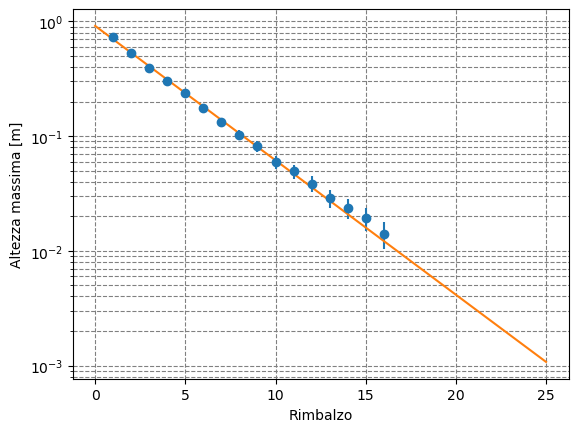

In [3]:
t = [1.254, 2.026, 2.682, 3.247, 3.743, 4.182, 4.562, 4.890, 5.179, 5.437, 5.657, 5.858, 6.035, 6.188, 6.327, 6.452, 6.559]

# Supponiamo di aver preso a mano questa serie di tempi di rimbalzo.
# Cercate di stimare ragionevolmente gli errori...
sigma_t = 0.01
# Calcolo delle differenze di tempo.
dt = np.diff(t)
# Creazione dell’array con gli indici dei rimbalzi.
n = np.arange(len(dt)) + 1.
# Calcolo dell’altezza massima e propagazione degli errori.
h = 9.81 * (dt**2.) / 8.0
dh = 2.0 * np.sqrt(2.0) * h * sigma_t / dt

def expo(n, h0, gamma):
    """Modello di fit."""
    return h0 * gamma**n

plt.figure('Altezza dei rimbalzi')
plt.errorbar(n, h, dh, fmt='o')
popt, pcov = curve_fit(expo, n, h, sigma=dh)
h0_hat, gamma_hat = popt
sigma_h0, sigma_gamma = np.sqrt(pcov.diagonal())
print(h0_hat, sigma_h0, gamma_hat, sigma_gamma)
x = np.linspace(0.0, 25.0, 100)
plt.plot(x, expo(x, h0_hat, gamma_hat))
plt.yscale('log')
plt.grid(which='both', ls='dashed', color='gray')
plt.xlabel('Rimbalzo')
plt.ylabel('Altezza massima [m]')
plt.savefig('bounces.png')

plt.show()

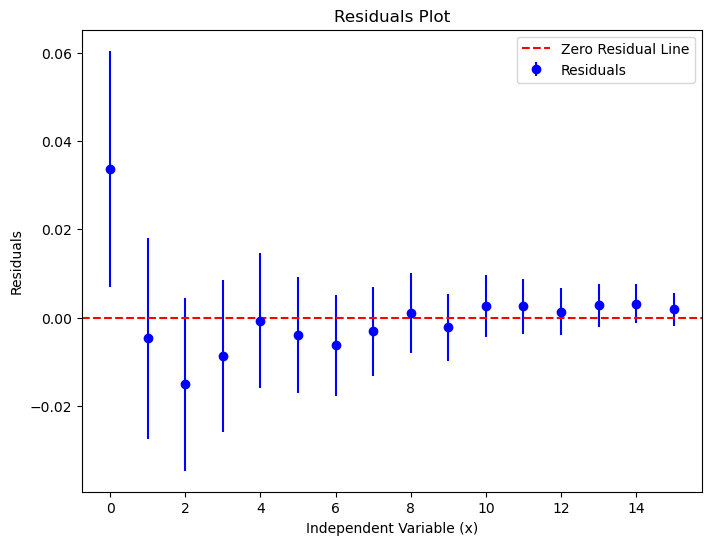

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Calculate residuals: y-y_pred
residuals = h - expo(n, h0_hat, gamma_hat)

# Plot the residuals - remember to put the y error of the thing
plt.figure(figsize=(8, 6))
plt.errorbar(range(len(residuals)), residuals, yerr=dh, color='blue', label='Residuals', fmt='o')

plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual Line')
plt.xlabel('Independent Variable (x)')
plt.ylabel('Residuals')
plt.title('Residuals Plot')
plt.legend()
plt.show()

i primi non ridanno, forse perchè la palla parte dall'alto e la resistenza dell'aria non è trascurabile?


il primo rumorino che si vede nel tracciato è quando rilascio la palla, NON è un rimbalzo, quindi non è nella lista t
ho notato dopo che non serviva, visto che si prende l'intervallo tra due rimbalzi consecutivi

In [5]:
chi = np.sum((residuals/dh)**2) 

print(chi)

4.539316979358452
